In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [76]:
df =pd.read_csv('sleep_debt_screen_time.csv')

In [77]:
df.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [78]:
df["blue_light_filter_on"] = df["blue_light_filter_on"].astype(int)
df.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,0,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,1,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,1,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,0,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,1,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [79]:
categorical_variable = df.columns[df.dtypes == 'str'].drop('sleep_debt_category').tolist()
categorical_variable

['gender', 'chronotype', 'occupation', 'primary_app_category']

In [80]:
numerical_variable = df.columns[df.dtypes != 'str'].drop('next_day_fatigue_score').tolist()
numerical_variable

['user_id',
 'age',
 'bedtime_hour',
 'screen_time_before_bed_min',
 'screen_brightness_pct',
 'blue_light_filter_on',
 'caffeine_intake_mg',
 'caffeine_last_hour',
 'physical_activity_min',
 'room_temperature_f',
 'ambient_noise_db',
 'sleep_onset_latency_min',
 'total_sleep_hours',
 'rem_sleep_pct',
 'deep_sleep_pct',
 'awakenings_count',
 'sleep_efficiency_pct']

<Axes: xlabel='next_day_fatigue_score', ylabel='Count'>

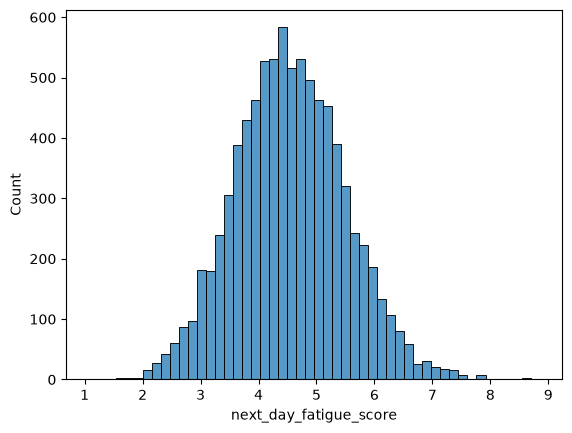

In [81]:
sns.histplot(df.next_day_fatigue_score, bins=50)

In [82]:
df.isnull().sum()

user_id                       0
age                           0
gender                        0
chronotype                    0
occupation                    0
bedtime_hour                  0
screen_time_before_bed_min    0
primary_app_category          0
screen_brightness_pct         0
blue_light_filter_on          0
caffeine_intake_mg            0
caffeine_last_hour            0
physical_activity_min         0
room_temperature_f            0
ambient_noise_db              0
sleep_onset_latency_min       0
total_sleep_hours             0
rem_sleep_pct                 0
deep_sleep_pct                0
awakenings_count              0
sleep_efficiency_pct          0
next_day_fatigue_score        0
sleep_debt_category           0
dtype: int64

In [83]:
df.sleep_debt_category.value_counts(normalize=True)

sleep_debt_category
Mild        0.516824
Moderate    0.277765
No Debt     0.202471
Severe      0.002941
Name: proportion, dtype: float64

In [84]:
for col in categorical_variable:
    print(col)
    print(df[col].unique())
    print(df[col].nunique())
    print()

gender
<StringArray>
['Female', 'Male', 'Non-Binary']
Length: 3, dtype: str
3

chronotype
<StringArray>
['Intermediate', 'Night Owl', 'Early Bird']
Length: 3, dtype: str
3

occupation
<StringArray>
['Student', 'Professional', 'Retired', 'Unemployed', 'Freelancer']
Length: 5, dtype: str
5

primary_app_category
<StringArray>
[    'Social Media', 'Short-Form Video',        'Messaging',
        'Streaming',        'E-Reading',           'Gaming',
             'News']
Length: 7, dtype: str
7



In [85]:
mean_next_day_fatigue_score = df.next_day_fatigue_score.mean()
mean_next_day_fatigue_score

np.float64(4.54989294117647)

In [86]:
for c in categorical_variable:
    print(c)
    df_group = df.groupby(c).next_day_fatigue_score.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - mean_next_day_fatigue_score
    df_group['risk'] = df_group['mean'] / mean_next_day_fatigue_score
    display(df_group)
    print()
    print()


c= 'blue_light_filter_on'
print(c)
df_group = df.groupby(c).next_day_fatigue_score.agg(['mean', 'count'])
df_group['diff'] = df_group['mean'] - mean_next_day_fatigue_score
df_group['risk'] = df_group['mean'] / mean_next_day_fatigue_score
display(df_group)
print()
print()
    

gender


,mean,count,diff,risk
gender,,,,
Female,4.547319,4106,-0.002574,0.999434
Male,4.545529,4048,-0.004364,0.999041
Non-Binary,4.631503,346,0.081610,1.017937




chronotype


,mean,count,diff,risk
chronotype,,,,
Early Bird,4.370334,2067,-0.179559,0.960536
Intermediate,4.516004,3466,-0.033889,0.992552
Night Owl,4.714574,2967,0.164681,1.036194




occupation


,mean,count,diff,risk
occupation,,,,
Freelancer,4.532763,1256,-0.017130,0.996235
Professional,4.533403,2980,-0.016490,0.996376
Retired,4.609540,847,0.059647,1.013109
Student,4.553056,2588,0.003163,1.000695
Unemployed,4.564306,829,0.014413,1.003168




primary_app_category


,mean,count,diff,risk
primary_app_category,,,,
E-Reading,4.037089,711,-0.512804,0.887293
Gaming,4.671236,882,0.121343,1.026669
Messaging,4.455910,753,-0.093983,0.979344
News,4.421138,659,-0.128755,0.971702
Short-Form Video,4.745357,2468,0.195464,1.042960
Social Media,4.611298,1834,0.061405,1.013496
Streaming,4.397485,1193,-0.152408,0.966503




blue_light_filter_on


,mean,count,diff,risk
blue_light_filter_on,,,,
0,4.641481,5563,0.091588,1.020130
1,4.376415,2937,-0.173478,0.961872


In [87]:
from sklearn.metrics import mutual_info_score

In [88]:
def mutual_info_next_day_fatigue(series):
    return mutual_info_score(series, df.next_day_fatigue_score)

def mutual_info_sleep_debt_category(series):
    return mutual_info_score(series, df.sleep_debt_category)


In [89]:
mi = df[categorical_variable].apply(mutual_info_sleep_debt_category)
mi.sort_values(ascending=False)

chronotype              0.048228
primary_app_category    0.002946
occupation              0.000716
gender                  0.000326
dtype: float64

In [90]:
df[numerical_variable].corrwith(df.next_day_fatigue_score).abs().sort_values(ascending=False)

total_sleep_hours             0.688568
sleep_efficiency_pct          0.536935
sleep_onset_latency_min       0.479315
awakenings_count              0.440525
rem_sleep_pct                 0.337327
screen_time_before_bed_min    0.336067
age                           0.278334
caffeine_intake_mg            0.261541
deep_sleep_pct                0.190759
screen_brightness_pct         0.176128
blue_light_filter_on          0.132120
bedtime_hour                  0.132016
caffeine_last_hour            0.131273
ambient_noise_db              0.067587
physical_activity_min         0.016990
user_id                       0.013405
room_temperature_f            0.011141
dtype: float64

In [91]:
from sklearn.model_selection import train_test_split

In [92]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [93]:
y_train_numerical = df_train.next_day_fatigue_score.values
y_val_numerical = df_val.next_day_fatigue_score.values
y_test_numerical = df_test.next_day_fatigue_score.values
y_train_categorical = df_train.sleep_debt_category.values
y_val_categorical = df_val.sleep_debt_category.values
y_test_categorical = df_test.sleep_debt_category.values

In [94]:
df_train = df_train.drop(labels=['next_day_fatigue_score','sleep_debt_category'],axis=1)
df_val = df_val.drop(labels=['next_day_fatigue_score','sleep_debt_category'],axis=1)
df_test = df_test.drop(labels=['next_day_fatigue_score','sleep_debt_category'],axis=1)

In [95]:
df_train.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct
6853,6854,16,Female,Night Owl,Professional,1.85,41,Social Media,96,1,...,21.7,14,71.6,26.2,34.4,6.73,15.7,19.2,5,75.8
3314,3315,24,Non-Binary,Early Bird,Student,22.31,45,Social Media,51,1,...,10.9,56,71.9,40.5,24.3,8.67,16.8,17.6,4,80.9
8113,8114,16,Male,Intermediate,Professional,23.38,43,Social Media,84,0,...,18.5,53,71.3,34.0,25.7,7.10,20.3,15.7,2,77.5
816,817,30,Female,Early Bird,Professional,22.47,64,Short-Form Video,51,0,...,17.9,11,68.4,35.0,36.2,6.87,10.6,14.7,3,80.4
771,772,22,Female,Early Bird,Professional,22.07,46,Messaging,67,1,...,13.2,22,75.1,41.1,25.5,7.93,17.5,16.5,0,85.7


In [96]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

In [97]:
scaler = StandardScaler()
#scaler = MinMaxScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

In [98]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_cat = ohe.fit_transform(df_train[categorical_variable].values)
X_val_cat   = ohe.transform(df_val[categorical_variable].values)

In [99]:
ohe.get_feature_names_out()

array(['x0_Female', 'x0_Male', 'x0_Non-Binary', 'x1_Early Bird',
       'x1_Intermediate', 'x1_Night Owl', 'x2_Freelancer',
       'x2_Professional', 'x2_Retired', 'x2_Student', 'x2_Unemployed',
       'x3_E-Reading', 'x3_Gaming', 'x3_Messaging', 'x3_News',
       'x3_Short-Form Video', 'x3_Social Media', 'x3_Streaming'],
      dtype=object)

In [100]:
X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

In [101]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [102]:
lr = LinearRegression()

lr.fit(X_train, y_train_numerical)

y_pred = lr.predict(X_val)

root_mean_squared_error(y_val_numerical, y_pred)

0.4179289887988116

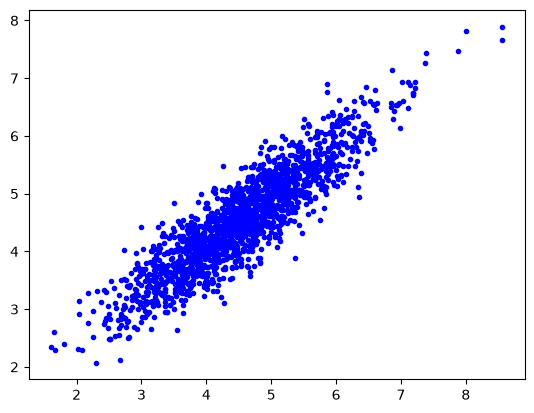

In [103]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [104]:


X_train_num = df_train[numerical_variable].values
X_val_num = df_val[numerical_variable].values

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.41792898879881113

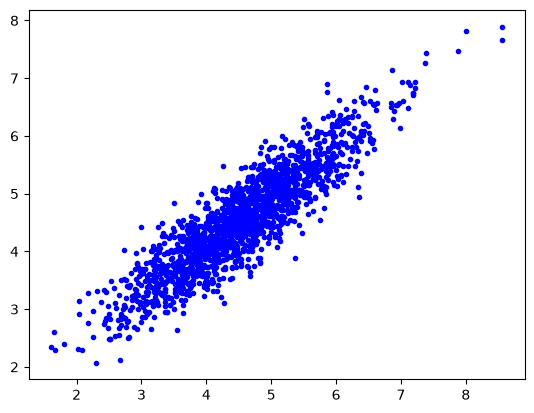

In [105]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [106]:
#scaler = StandardScaler()
sacler = MinMaxScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.4179289887988116

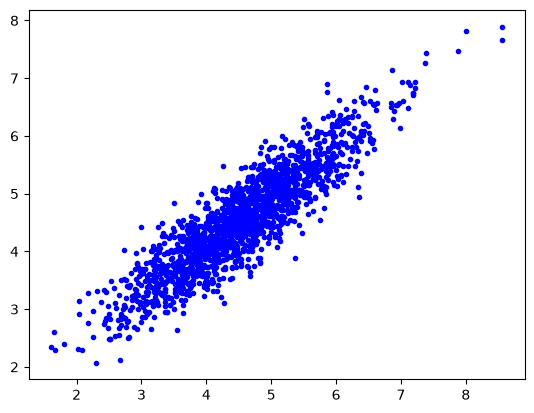

In [107]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [108]:
from sklearn.feature_extraction import DictVectorizer

In [109]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_variable + numerical_variable].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical_variable + numerical_variable].to_dict(orient='records')
X_val = dv.transform(val_dict)

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.4179289887988117

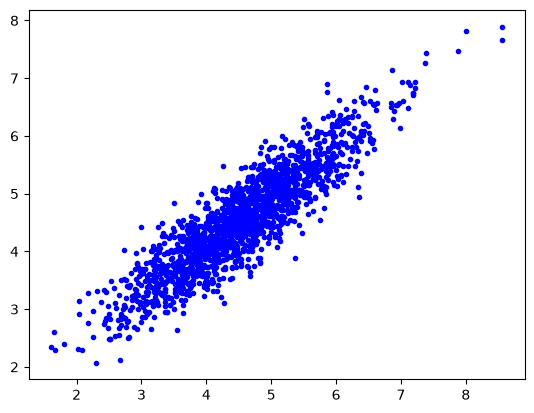

In [110]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [111]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.4179289887988116

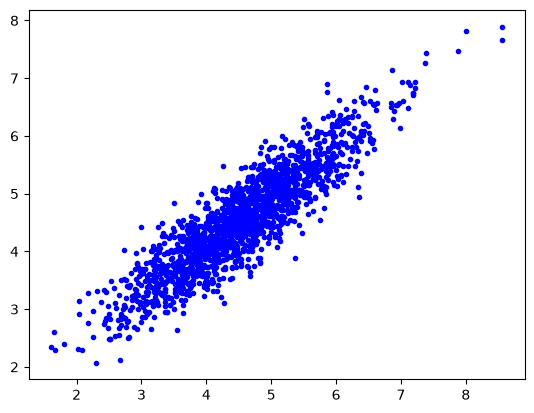

In [112]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [113]:
lr.coef_

array([ 0.00660437,  0.00853135,  0.01595787,  0.1379212 ,  0.07370984,
       -0.07333803,  0.059143  ,  0.03971194, -0.0022636 , -0.0021335 ,
       -0.01065785,  0.03771336, -0.59691724, -0.11072632, -0.00592306,
        0.24211359, -0.15291256, -0.00606144, -0.01803991,  0.02410135,
       -0.00086046, -0.00517744,  0.0060379 ,  0.01175991, -0.01292566,
        0.00078202, -0.00831108,  0.00869481, -0.32519185,  0.13674232,
       -0.0039747 , -0.08417682,  0.19726262,  0.10779451, -0.02845608])

In [114]:
from sklearn.linear_model import Ridge

In [115]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    rid = Ridge(alpha= alpha)
    rid.fit(X_train, y_train_numerical)
    y_pred = rid.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.4179289888337615
alpha=0.001, rmse=0.41792898914846294
alpha=0.01, rmse=0.4179289923106396
alpha=0.1, rmse=0.4179290254478351
alpha=1, rmse=0.4179295075912123
alpha=10, rmse=0.41794866785677637
alpha=100, rmse=0.4190694340842816


In [116]:
rid.coef_

array([ 0.00639123,  0.01370909,  0.0111304 ,  0.13106693,  0.06978056,
       -0.06936508,  0.05118532,  0.0351256 , -0.00135756, -0.00407279,
       -0.01273561,  0.05733935, -0.57877512, -0.11958719, -0.00597596,
        0.23592739, -0.15294248, -0.00449864, -0.01580083,  0.02029947,
       -0.00425478, -0.0052352 ,  0.00948998,  0.00829017, -0.01117025,
        0.0013674 , -0.00700831,  0.00852099, -0.24808146,  0.10213932,
       -0.00895751, -0.06721157,  0.16373171,  0.08568551, -0.027306  ])

In [117]:
categorical_variable =['primary_app_category']

In [118]:
numerical_variable = list(df[df.columns[df.dtypes != 'str'].drop('next_day_fatigue_score').tolist()].corrwith(df.next_day_fatigue_score).abs().sort_values(ascending=False).index[:14])
numerical_variable

['total_sleep_hours',
 'sleep_efficiency_pct',
 'sleep_onset_latency_min',
 'awakenings_count',
 'rem_sleep_pct',
 'screen_time_before_bed_min',
 'age',
 'caffeine_intake_mg',
 'deep_sleep_pct',
 'screen_brightness_pct',
 'blue_light_filter_on',
 'bedtime_hour',
 'caffeine_last_hour',
 'ambient_noise_db']

In [119]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_cat = ohe.fit_transform(df_train[categorical_variable].values)
X_val_cat   = ohe.transform(df_val[categorical_variable].values)

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])



In [120]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    rid = Ridge(alpha= alpha)
    rid.fit(X_train, y_train_numerical)
    y_pred = rid.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.41823050386227867
alpha=0.001, rmse=0.41823050419706514
alpha=0.01, rmse=0.41823050755988067
alpha=0.1, rmse=0.4182305426823914
alpha=1, rmse=0.41823104258614635
alpha=10, rmse=0.4182501849523208
alpha=100, rmse=0.41935961189260507


In [121]:
alpha=1
rid = Ridge(alpha= alpha)
rid.fit(X_train, y_train_numerical)
y_pred = rid.predict(X_val)
print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
rid.coef_

alpha=1, rmse=0.41823104258614635


array([-0.59663958, -0.15312835,  0.03717676,  0.24230351, -0.11066121,
        0.13813031,  0.00875332,  0.05914361, -0.00693742,  0.07367971,
       -0.07370747,  0.01293427,  0.03976833, -0.01067973, -0.32451502,
        0.13716245, -0.00377639, -0.08424573,  0.19702826,  0.10719744,
       -0.02885101])

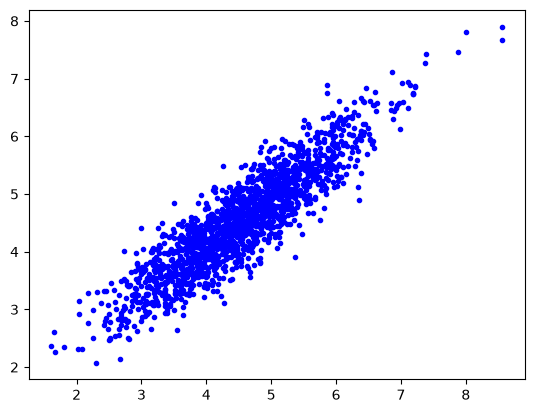

In [122]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [123]:
from sklearn.linear_model import Lasso

In [124]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    las = Lasso(alpha= alpha)
    las.fit(X_train, y_train_numerical)
    y_pred = las.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.4182219270860263
alpha=0.001, rmse=0.4182368836428901
alpha=0.01, rmse=0.42474424894731566
alpha=0.1, rmse=0.47387087622733226
alpha=1, rmse=0.9653325639386586
alpha=10, rmse=0.9653325639386586
alpha=100, rmse=0.9653325639386586


In [125]:
for alpha in [0.0001, 0.00025, 0.0005, 0.001, 0.0025, 0.005, 0.01]:
    las = Lasso(alpha= alpha)
    las.fit(X_train, y_train_numerical)
    y_pred = las.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.4182219270860263
alpha=0.00025, rmse=0.4182133174965089
alpha=0.0005, rmse=0.418208978494356
alpha=0.001, rmse=0.4182368836428901
alpha=0.0025, rmse=0.4186109910084752
alpha=0.005, rmse=0.4199772420870779
alpha=0.01, rmse=0.42474424894731566


In [126]:
alpha=0.0005
las = Lasso(alpha= alpha)
las.fit(X_train, y_train_numerical)
y_pred = las.predict(X_val)
print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
las.coef_

alpha=0.0005, rmse=0.418208978494356


array([-0.5963771 , -0.15315693,  0.03937361,  0.24182239, -0.11209298,
        0.1369729 ,  0.00777903,  0.0575579 , -0.00657935,  0.0728338 ,
       -0.07283232,  0.01213352,  0.03864529, -0.01049024, -0.31196131,
        0.13470827, -0.        , -0.07367042,  0.19669406,  0.10743727,
       -0.02116053])

In [127]:
from sklearn.linear_model import ElasticNet

In [128]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    print(alpha)
    for l1_ratio in range(11):
        elnet = ElasticNet(alpha= alpha, l1_ratio=l1_ratio/10)
        elnet.fit(X_train, y_train_numerical)
        y_pred = elnet.predict(X_val)
        print (f'alpha={alpha}, l1_ratio={l1_ratio}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
    print()

0.0001
alpha=0.0001, l1_ratio=0, rmse=0.4182309597576756
alpha=0.0001, l1_ratio=1, rmse=0.4182293636629513
alpha=0.0001, l1_ratio=2, rmse=0.41822874955192824
alpha=0.0001, l1_ratio=3, rmse=0.41822783335378433
alpha=0.0001, l1_ratio=4, rmse=0.4182269453504648


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.302511e+01, tolerance: 4.584e-01
  model = cd_fast.enet_coordinate_descent(


alpha=0.0001, l1_ratio=5, rmse=0.4182260607879082
alpha=0.0001, l1_ratio=6, rmse=0.41822522953744257
alpha=0.0001, l1_ratio=7, rmse=0.4182243967035013
alpha=0.0001, l1_ratio=8, rmse=0.418223567855601
alpha=0.0001, l1_ratio=9, rmse=0.4182227960382027
alpha=0.0001, l1_ratio=10, rmse=0.4182219270860263

0.001
alpha=0.001, l1_ratio=0, rmse=0.4182368766140076
alpha=0.001, l1_ratio=1, rmse=0.4182285409987032
alpha=0.001, l1_ratio=2, rmse=0.41822375065648
alpha=0.001, l1_ratio=3, rmse=0.41822040387420495
alpha=0.001, l1_ratio=4, rmse=0.41821847649788957
alpha=0.001, l1_ratio=5, rmse=0.4182180851131321
alpha=0.001, l1_ratio=6, rmse=0.41821909429634874
alpha=0.001, l1_ratio=7, rmse=0.4182212679197263
alpha=0.001, l1_ratio=8, rmse=0.4182250915344093
alpha=0.001, l1_ratio=9, rmse=0.41823020871202693
alpha=0.001, l1_ratio=10, rmse=0.4182368836428901

0.01
alpha=0.01, l1_ratio=0, rmse=0.4185940218559011
alpha=0.01, l1_ratio=1, rmse=0.41873945855850564
alpha=0.01, l1_ratio=2, rmse=0.4190301776242581

In [129]:
for alpha in [0.0005, 0.001, 0.002]:
    print(alpha)
    for l1_ratio in [7, 7.5, 8, 8.5, 9]:
        elnet = ElasticNet(alpha= alpha, l1_ratio=l1_ratio/10)
        elnet.fit(X_train, y_train_numerical)
        y_pred = elnet.predict(X_val)
        print (f'alpha={alpha}, l1_ratio={l1_ratio}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
    print()

0.0005
alpha=0.0005, l1_ratio=7, rmse=0.4182118966937474
alpha=0.0005, l1_ratio=7.5, rmse=0.418211343726236
alpha=0.0005, l1_ratio=8, rmse=0.41821061100207196
alpha=0.0005, l1_ratio=8.5, rmse=0.4182100943301776
alpha=0.0005, l1_ratio=9, rmse=0.4182096108706433

0.001
alpha=0.001, l1_ratio=7, rmse=0.4182212679197263
alpha=0.001, l1_ratio=7.5, rmse=0.41822311808425844
alpha=0.001, l1_ratio=8, rmse=0.4182250915344093
alpha=0.001, l1_ratio=8.5, rmse=0.41822758562592205
alpha=0.001, l1_ratio=9, rmse=0.41823020871202693

0.002
alpha=0.002, l1_ratio=7, rmse=0.41832001457897455
alpha=0.002, l1_ratio=7.5, rmse=0.4183360577992329
alpha=0.002, l1_ratio=8, rmse=0.4183533764075902
alpha=0.002, l1_ratio=8.5, rmse=0.4183721626103438
alpha=0.002, l1_ratio=9, rmse=0.4183926356763555



In [130]:
alpha = 0.001
l1_ratio=8
elnet = ElasticNet(alpha= alpha, l1_ratio=l1_ratio/10)
elnet.fit(X_train, y_train_numerical)
y_pred = elnet.predict(X_val)
print (f'alpha={alpha}, l1_ratio={l1_ratio}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

elnet.coef_

alpha=0.001, l1_ratio=8, rmse=0.4182250915344093


array([-0.5959198 , -0.15317208,  0.04107417,  0.241426  , -0.11313917,
        0.13614524,  0.0072687 ,  0.05644226, -0.00635262,  0.07225152,
       -0.07222964,  0.01153726,  0.03787987, -0.0104207 , -0.30492258,
        0.13045586, -0.        , -0.06908156,  0.19375072,  0.10505632,
       -0.01863857])

In [131]:
from sklearn.model_selection import GridSearchCV


In [132]:
parameters = {'alpha':[0.0001, 0.00025, 0.0005, 0.001, 0.002], 'l1_ratio':[0.7+i/20 for i in range(7)]}
elnet =ElasticNet()
clf = GridSearchCV(elnet, parameters, scoring='neg_root_mean_squared_error')
clf.fit(X_train, y_train_numerical)
print(clf.best_params_)
print(-clf.best_score_)

{'alpha': 0.0001, 'l1_ratio': 0.7}
0.40772477547418157


In [98]:
from sklearn.tree import DecisionTreeRegressor

In [99]:
scores =[]

for max_d in range(1,21):
    score =[]
    for min_sl in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeRegressor(max_depth=max_d, min_samples_leaf=min_sl)
        dt.fit(X_train, y_train_numerical)
        y_pred = dt.predict(X_val)
        score.append(root_mean_squared_error(y_val_numerical, y_pred))
        print (f'max_depth={max_d}, min_sample_leaf={min_sl}, rmse={score[-1]}')
    scores.append(score)

scores

max_depth=1, min_sample_leaf=1, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=5, rmse=0.8152289218938081
max_depth=1, min_sample_leaf=10, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=15, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=20, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=500, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=100, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=200, rmse=0.8152289218938086
max_depth=2, min_sample_leaf=1, rmse=0.7188284480687511
max_depth=2, min_sample_leaf=5, rmse=0.7188284480687512
max_depth=2, min_sample_leaf=10, rmse=0.7188284480687511
max_depth=2, min_sample_leaf=15, rmse=0.7188284480687512
max_depth=2, min_sample_leaf=20, rmse=0.7188284480687511
max_depth=2, min_sample_leaf=500, rmse=0.7188284480687512
max_depth=2, min_sample_leaf=100, rmse=0.7188284480687511
max_depth=2, min_sample_leaf=200, rmse=0.7188284480687513
max_depth=3, min_sample_leaf=1, rmse=0.6500290556873001
max_depth=3, min_sample_leaf=5

[[0.8152289218938084,
  0.8152289218938081,
  0.8152289218938084,
  0.8152289218938084,
  0.8152289218938084,
  0.8152289218938084,
  0.8152289218938084,
  0.8152289218938086],
 [0.7188284480687511,
  0.7188284480687512,
  0.7188284480687511,
  0.7188284480687512,
  0.7188284480687511,
  0.7188284480687512,
  0.7188284480687511,
  0.7188284480687513],
 [0.6500290556873001,
  0.6500290556873001,
  0.6500290556873002,
  0.6500290556873003,
  0.6500290556873,
  0.6625465178835541,
  0.6500290556873001,
  0.6500290556873001],
 [0.6009104369334792,
  0.6009104369334792,
  0.6009104369334793,
  0.6009104369334793,
  0.6009104369334792,
  0.6542518507244427,
  0.6026325296911678,
  0.6086528977667444],
 [0.5765624531416461,
  0.5765624531416462,
  0.5777110876596516,
  0.5782897184259878,
  0.5756079417711147,
  0.6542518507244427,
  0.5885091506477536,
  0.6004500728610638],
 [0.5574068194539215,
  0.5586402880456198,
  0.5570368889022304,
  0.5598397202728589,
  0.5563771050891899,
  0.6542

<Axes: >

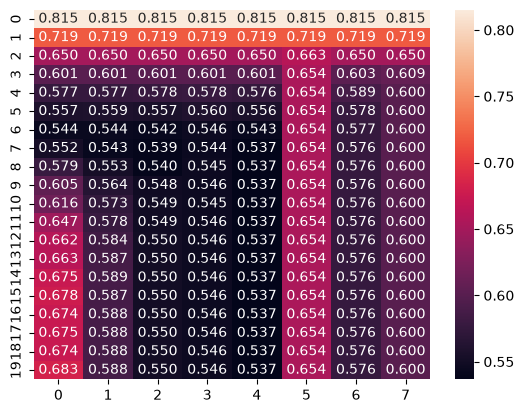

In [100]:
sns.heatmap(scores, annot=True, fmt=".3f")

In [101]:
from sklearn.ensemble import RandomForestRegressor

In [102]:
scores =[]

for max_d in range(1,21):
    score =[]
    for n_est in [10, 20, 50, 100, 200, 500, 1000]:
        rf = RandomForestRegressor(max_depth=max_d, n_estimators=n_est)
        rf.fit(X_train, y_train_numerical)
        y_pred = rf.predict(X_val)
        score.append(root_mean_squared_error(y_val_numerical, y_pred))
        print (f'max_depth={max_d}, n_estimators={n_est}, rmse={score[-1]}')
    scores.append(score)

scores

max_depth=1, n_estimators=10, rmse=0.7943578394838307
max_depth=1, n_estimators=20, rmse=0.796939641533446
max_depth=1, n_estimators=50, rmse=0.7927434926485547
max_depth=1, n_estimators=100, rmse=0.7952100838771771
max_depth=1, n_estimators=200, rmse=0.7971956477185997
max_depth=1, n_estimators=500, rmse=0.796354495414754
max_depth=1, n_estimators=1000, rmse=0.7961071021991611
max_depth=2, n_estimators=10, rmse=0.6898324232513776
max_depth=2, n_estimators=20, rmse=0.6820807548655655
max_depth=2, n_estimators=50, rmse=0.6861076314483716
max_depth=2, n_estimators=100, rmse=0.6835163712131345
max_depth=2, n_estimators=200, rmse=0.682549262681366
max_depth=2, n_estimators=500, rmse=0.683131818095227
max_depth=2, n_estimators=1000, rmse=0.6807865460610835
max_depth=3, n_estimators=10, rmse=0.6117803400488978
max_depth=3, n_estimators=20, rmse=0.6161387699926668
max_depth=3, n_estimators=50, rmse=0.6122586987888096
max_depth=3, n_estimators=100, rmse=0.614412742821748
max_depth=3, n_estimat

[[0.7943578394838307,
  0.796939641533446,
  0.7927434926485547,
  0.7952100838771771,
  0.7971956477185997,
  0.796354495414754,
  0.7961071021991611],
 [0.6898324232513776,
  0.6820807548655655,
  0.6861076314483716,
  0.6835163712131345,
  0.682549262681366,
  0.683131818095227,
  0.6807865460610835],
 [0.6117803400488978,
  0.6161387699926668,
  0.6122586987888096,
  0.614412742821748,
  0.614777202002931,
  0.6140017125257812,
  0.6146163501859345],
 [0.5664428323495245,
  0.5657815878971648,
  0.560296444615856,
  0.5592637231749716,
  0.5603961776094876,
  0.5610055855905711,
  0.5603941210249395],
 [0.5287853564146688,
  0.529120006388462,
  0.5244005015134083,
  0.5247999733504639,
  0.5239410305143402,
  0.5226558530646026,
  0.5237517889359328],
 [0.504473140160434,
  0.5027842052766843,
  0.4999951208405188,
  0.4980255157649418,
  0.49795856343894,
  0.49771848006788766,
  0.4974754658576847],
 [0.4940257751284635,
  0.48443994817243147,
  0.4845954450061203,
  0.481966737

<Axes: >

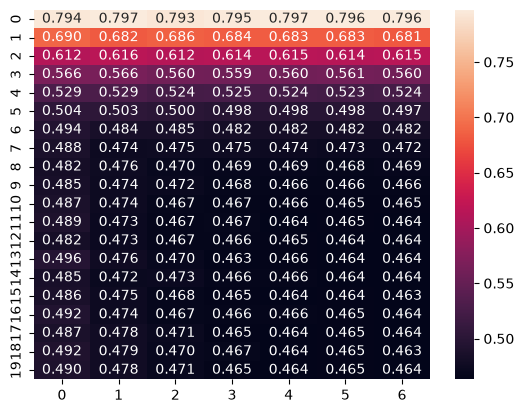

In [103]:
sns.heatmap(scores, annot=True, fmt=".3f")

In [54]:
from sklearn.kernel_ridge import KernelRidge

In [55]:
scores =[]

alpha=1
kernel = 'poly'
for gamma in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    score =[]
    for degree in range(1,6):
        kr = KernelRidge(alpha=alpha,gamma=gamma,kernel=kernel,degree=degree)
        kr.fit(X_train, y_train_numerical)
        y_pred = kr.predict(X_val)
        score.append(root_mean_squared_error(y_val_numerical, y_pred))
        print (f'gamma={gamma}, degree={degree}, rmse={score[-1]}')
    scores.append(score)
scores

gamma=0.0001, degree=1, rmse=0.6222842035812216
gamma=0.0001, degree=2, rmse=0.5387878945555172
gamma=0.0001, degree=3, rmse=0.5023756955183322
gamma=0.0001, degree=4, rmse=0.48219869631282053
gamma=0.0001, degree=5, rmse=0.46944776528899523
gamma=0.001, degree=1, rmse=0.44278313453250073
gamma=0.001, degree=2, rmse=0.42907371266416244
gamma=0.001, degree=3, rmse=0.42439884803199507
gamma=0.001, degree=4, rmse=0.4219014554763352
gamma=0.001, degree=5, rmse=0.42024386068186126
gamma=0.01, degree=1, rmse=0.4194189149253248
gamma=0.01, degree=2, rmse=0.41413480291632476
gamma=0.01, degree=3, rmse=0.41394252409106647
gamma=0.01, degree=4, rmse=0.41478756369510394
gamma=0.01, degree=5, rmse=0.4163370155215445
gamma=0.1, degree=1, rmse=0.4183093877976775
gamma=0.1, degree=2, rmse=0.41764162015991074
gamma=0.1, degree=3, rmse=0.4686185983016928
gamma=0.1, degree=4, rmse=0.5979252169675606
gamma=0.1, degree=5, rmse=1.2128338476251508
gamma=1, degree=1, rmse=0.41829561989264546
gamma=1, degree=

[[0.6222842035812216,
  0.5387878945555172,
  0.5023756955183322,
  0.48219869631282053,
  0.46944776528899523],
 [0.44278313453250073,
  0.42907371266416244,
  0.42439884803199507,
  0.4219014554763352,
  0.42024386068186126],
 [0.4194189149253248,
  0.41413480291632476,
  0.41394252409106647,
  0.41478756369510394,
  0.4163370155215445],
 [0.4183093877976775,
  0.41764162015991074,
  0.4686185983016928,
  0.5979252169675606,
  1.2128338476251508],
 [0.41829561989264546,
  0.4184351469471891,
  0.552475203837158,
  1.9370289247505796,
  3.988653498795474],
 [0.4183040253253893,
  0.4183950040856712,
  0.5614274529815948,
  2.3408645427857127,
  5.1993247297771985],
 [0.41830680042867885,
  0.4183940950640184,
  0.5614407678067339,
  2.397502701722861,
  5.337386959254844]]

In [56]:
scores =[]
degree =3

kernel = 'poly'
for gamma in [0.001, 0.003, 0.01, 0.03, 0.1]:
    score =[]
    for alpha in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]:
        kr = KernelRidge(alpha=alpha,gamma=gamma,kernel=kernel,degree=degree)
        kr.fit(X_train, y_train_numerical)
        y_pred = kr.predict(X_val)
        score.append(root_mean_squared_error(y_val_numerical, y_pred))
        print (f'gamma={gamma}, alpha={alpha}, rmse={score[-1]}')
    scores.append(score)
scores

gamma=0.001, alpha=0.001, rmse=0.4164119441201841
gamma=0.001, alpha=0.003, rmse=0.41502791047611354
gamma=0.001, alpha=0.01, rmse=0.41357013738542747
gamma=0.001, alpha=0.03, rmse=0.4135684094363065
gamma=0.001, alpha=0.1, rmse=0.4154134082429742
gamma=0.001, alpha=0.3, rmse=0.41803384460490267
gamma=0.001, alpha=1, rmse=0.42439884803199507
gamma=0.001, alpha=3, rmse=0.4424947966168061
gamma=0.003, alpha=0.001, rmse=0.4218628014695073
gamma=0.003, alpha=0.003, rmse=0.41823255225586603
gamma=0.003, alpha=0.01, rmse=0.41632119008262075
gamma=0.003, alpha=0.03, rmse=0.4148715735363028
gamma=0.003, alpha=0.1, rmse=0.41356573574241856
gamma=0.003, alpha=0.3, rmse=0.4139518016611785
gamma=0.003, alpha=1, rmse=0.41697457390883685
gamma=0.003, alpha=3, rmse=0.42362207944059793
gamma=0.01, alpha=0.001, rmse=0.4692263789635177
gamma=0.01, alpha=0.003, rmse=0.4474307906759578
gamma=0.01, alpha=0.01, rmse=0.43111832190198174
gamma=0.01, alpha=0.03, rmse=0.422441176274042
gamma=0.01, alpha=0.1, rm

[[0.4164119441201841,
  0.41502791047611354,
  0.41357013738542747,
  0.4135684094363065,
  0.4154134082429742,
  0.41803384460490267,
  0.42439884803199507,
  0.4424947966168061],
 [0.4218628014695073,
  0.41823255225586603,
  0.41632119008262075,
  0.4148715735363028,
  0.41356573574241856,
  0.4139518016611785,
  0.41697457390883685,
  0.42362207944059793],
 [0.4692263789635177,
  0.4474307906759578,
  0.43111832190198174,
  0.422441176274042,
  0.41750825511338346,
  0.41522130499239834,
  0.41394252409106647,
  0.4151278422484912],
 [0.5301877465424807,
  0.5153370435027469,
  0.49144595463574675,
  0.4667006855811762,
  0.44365972249731606,
  0.42952366138126674,
  0.4204358738033236,
  0.41631544010136834],
 [0.551817218036291,
  0.5462525289018048,
  0.5401208087925718,
  0.5321001416941288,
  0.516801876069456,
  0.4957071442075988,
  0.4686185983016928,
  0.4467209906871717]]

In [57]:
degree =3
gamma = 0.003
alpha = 0.1
kernel = 'poly'
kr = KernelRidge(alpha=alpha,gamma=gamma,kernel=kernel,degree=degree)
kr.fit(X_train, y_train_numerical)
y_pred = kr.predict(X_val)
print (f'gamma={gamma}, alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')


gamma=0.003, alpha=0.1, rmse=0.41356573574241856


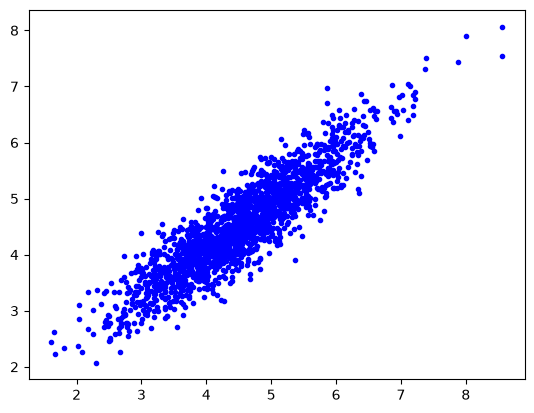

In [58]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [133]:
import xgboost as xgb

In [134]:
features = df_train[numerical_variable].columns.tolist()+ohe.get_feature_names_out(['primary_app_category']).tolist()
dtrain = xgb.DMatrix(X_train, label=y_train_numerical, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val_numerical, feature_names=features)

In [61]:
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)
y_pred = model.predict(dval)
print (f'rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

rmse=0.46932892011746113


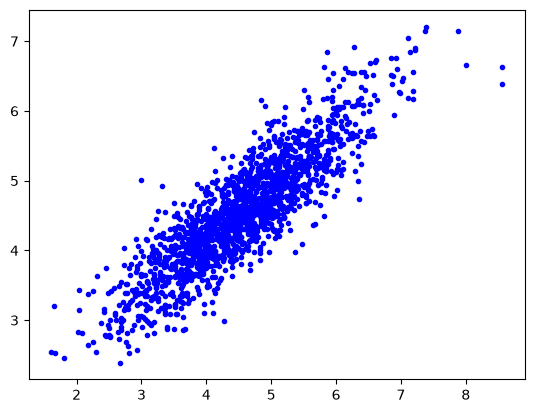

In [62]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [65]:
watchlist = [(dtrain, 'train'), (dval, 'val')]
scores = {}

In [68]:

def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [84]:
%%capture output

xgb_params = {
    'eta': 0.03, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)


In [85]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.03'

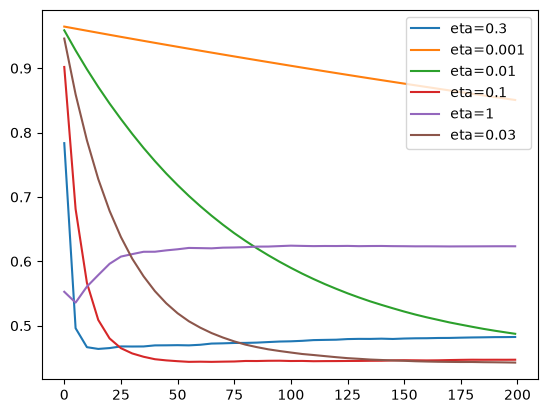

In [86]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)

#plt.ylim(0.8, 0.84)
plt.legend()

In [87]:
scores ={}

In [105]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 5,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)


In [106]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=5'

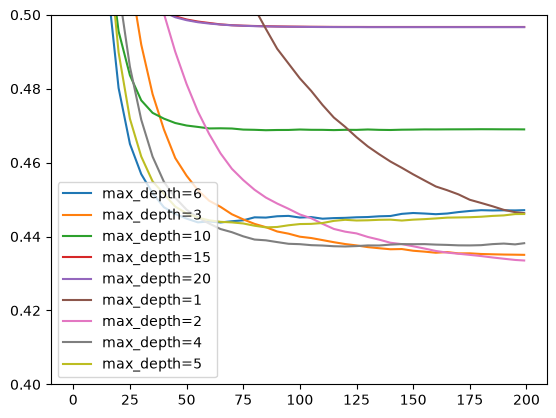

In [108]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)

plt.ylim(0.4, 0.5)
plt.legend()

In [109]:
scores ={}

In [118]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3,
    'min_child_weight': 50,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)


In [119]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=50'

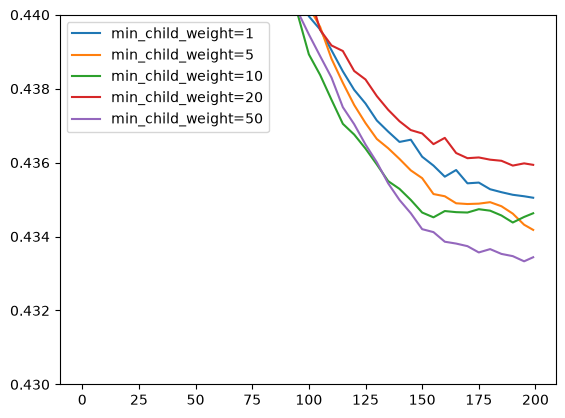

In [121]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)

plt.ylim(0.43, 0.44)
plt.legend()

In [122]:
scores ={}

In [129]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3,
    'min_child_weight': 10,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)


In [135]:
scores = parse_xgb_output(output)

In [137]:
scores

,num_iter,train_auc,val_auc
0,0,0.89483,0.91391
1,5,0.71053,0.73535
2,10,0.60693,0.63671
3,15,0.54363,0.57678
4,20,0.50040,0.53796
5,25,0.47204,0.51140
6,30,0.45282,0.49228
7,35,0.43836,0.47985
8,40,0.42777,0.46960
9,45,0.41961,0.46265


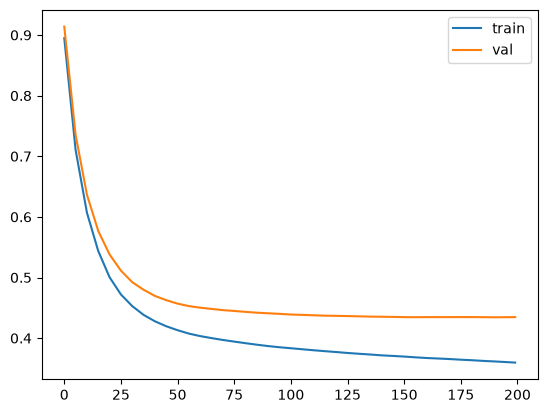

In [136]:
plt.plot(scores.num_iter, scores.train_auc, label='train')
plt.plot(scores.num_iter, scores.val_auc, label='val')
plt.legend()

In [139]:
y_pred = model.predict(dval)

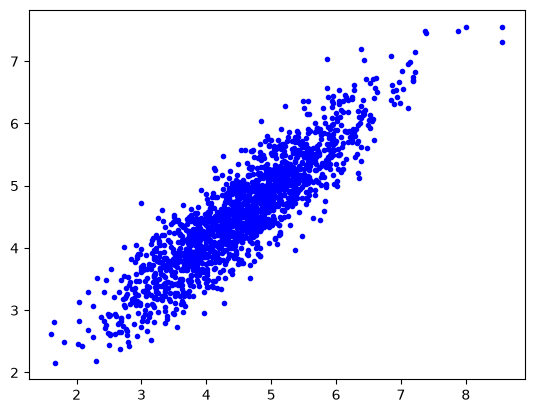

In [140]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [135]:
X_train_num = scaler.fit_transform(df_full_train[numerical_variable].values)
X_test_num = scaler.transform(df_test[numerical_variable].values)
X_train_cat = ohe.fit_transform(df_full_train[categorical_variable].values)
X_test_cat   = ohe.transform(df_test[categorical_variable].values)

X_train = np.column_stack([X_train_num, X_train_cat])
X_test = np.column_stack([X_test_num, X_test_cat])

y_train_numerical = df_full_train.next_day_fatigue_score.values

alpha=0.0005
las = Lasso(alpha= alpha)
las.fit(X_train, y_train_numerical)
y_pred = las.predict(X_test)
print (f'alpha={alpha}, rmse={root_mean_squared_error(y_test_numerical, y_pred)}')


alpha=0.0005, rmse=0.40600249881547834


In [136]:
df_features_effect = pd.DataFrame({'features':features, 'coef':las.coef_, 'abs(coef)':abs(las.coef_)}).sort_values(by='abs(coef)',ascending=False)
df_features_effect

,features,coef,abs(coef)
0,total_sleep_hours,-0.600169,0.600169
14,primary_app_category_E-Reading,-0.315365,0.315365
3,awakenings_count,0.244868,0.244868
18,primary_app_category_Short-Form Video,0.186620,0.186620
1,sleep_efficiency_pct,-0.152630,0.152630
5,screen_time_before_bed_min,0.133989,0.133989
15,primary_app_category_Gaming,0.125909,0.125909
4,rem_sleep_pct,-0.111924,0.111924
19,primary_app_category_Social Media,0.104756,0.104756
17,primary_app_category_News,-0.075915,0.075915


In [143]:
df_test.iloc[1].to_dict()

{'user_id': 2718,
 'age': 36,
 'gender': 'Non-Binary',
 'chronotype': 'Intermediate',
 'occupation': 'Professional',
 'bedtime_hour': 0.09,
 'screen_time_before_bed_min': 66,
 'primary_app_category': 'Streaming',
 'screen_brightness_pct': 67,
 'blue_light_filter_on': 0,
 'caffeine_intake_mg': 41,
 'caffeine_last_hour': 19.2,
 'physical_activity_min': 1,
 'room_temperature_f': 75.7,
 'ambient_noise_db': 36.5,
 'sleep_onset_latency_min': 31.4,
 'total_sleep_hours': 6.14,
 'rem_sleep_pct': 17.4,
 'deep_sleep_pct': 16.5,
 'awakenings_count': 4,
 'sleep_efficiency_pct': 77.8}

In [142]:
df_test.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct
3013,3014,16,Male,Night Owl,Freelancer,1.15,49,Messaging,74,0,...,16.7,39,67.9,40.0,38.6,7.24,19.9,19.8,0,80.4
2717,2718,36,Non-Binary,Intermediate,Professional,0.09,66,Streaming,67,0,...,19.2,1,75.7,36.5,31.4,6.14,17.4,16.5,4,77.8
1534,1535,23,Male,Early Bird,Professional,22.44,35,Gaming,76,0,...,11.2,73,69.7,22.6,32.5,8.13,13.8,18.4,2,83.3
5386,5387,41,Female,Night Owl,Unemployed,23.99,46,News,30,1,...,17.4,27,71.9,46.6,20.6,6.36,17.6,16.6,3,81.0
2353,2354,16,Male,Early Bird,Professional,21.57,72,Messaging,72,0,...,13.5,8,69.1,43.1,35.6,6.83,16.0,16.9,1,81.7


In [146]:
y_test_numerical[1]

np.float64(4.82)

In [147]:
y_pred

array([3.77729173, 5.35018053, 3.6959757 , ..., 4.43952454, 5.10048237,
       5.68725322], shape=(1700,))